# Ongoing 2 — Country investigation

Supplement to `Group_7_ongoing_2.ipynb`: investigate whether country and age composition help explain differences in the combined drug-use target.

**Questions**

1. How does the observed User rate vary by country?
2. Do the UK and USA have different age compositions?
3. Does their User-rate difference remain within the same age categories?

This notebook reads the existing cleaned SQLite table without modifying the database. User means reported use of at least one of the eight selected substances in the last month (CL4–CL6 in Report 1), not a clinical diagnosis or a prediction of future use.


In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

database_path = Path("sqlite3/database.sqlite3")
if not database_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from the project directory containing sqlite3/database.sqlite3."
    )

# Read-only connection; no ALTER TABLE or UPDATE statements.
with sqlite3.connect(database_path.resolve().as_uri() + "?mode=ro", uri=True) as connection:
    data_clean = pd.read_sql_query("SELECT * FROM data_clean", connection)

drug_columns = [
    "Amphet", "Cannabis", "Coke", "Ketamine",
    "LSD", "Mushrooms", "Legalh", "Ecstasy"
]
required = ["Country", "Age"] + drug_columns
assert data_clean[required].notna().all().all(), "Required values are missing."
assert data_clean[drug_columns].isin([0, 1]).all().all(), "Expected binary drug indicators."

# Recompute in memory to match Report 2, independently of any stored User column.
data_clean["User"] = data_clean[drug_columns].max(axis=1).astype(int)
sns.set_theme(style="whitegrid")
print(f"Records: {len(data_clean):,}")
print(f"Users: {data_clean['User'].sum():,}")
print(f"Overall User rate: {data_clean['User'].mean():.2%}")


Records: 1,885
Users: 921
Overall User rate: 48.86%


## 1. Country versus User

Compare **within-country percentages**, rather than raw User counts. Show group sizes and Wilson 95% confidence intervals to make small samples visible. The intervals describe binomial uncertainty under an independent-observation model; they do not account for recruitment bias or establish national representativeness.


,n,users,User rate (%),95% CI lower (%),95% CI upper (%)
Country,,,,,
UK,1044,247,23.66,21.18,26.33
USA,557,476,85.46,82.29,88.14
Other,118,84,71.19,62.45,78.59
Canada,87,52,59.77,49.26,69.45
Australia,54,45,83.33,71.26,90.98
Republic of Ireland,20,13,65.00,43.29,81.88
New Zealand,5,4,80.00,37.55,96.38


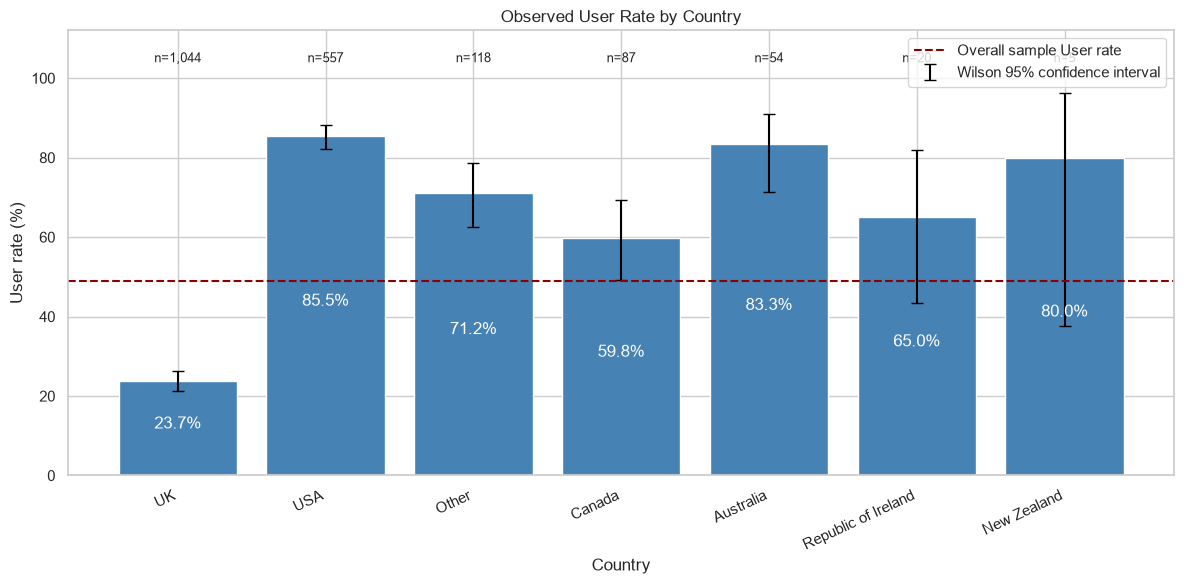

In [2]:
def wilson_interval(successes, totals, z=1.96):
    proportion = successes / totals
    denominator = 1 + z**2 / totals
    center = (proportion + z**2 / (2 * totals)) / denominator
    margin = z * np.sqrt(
        proportion * (1 - proportion) / totals + z**2 / (4 * totals**2)
    ) / denominator
    return (center - margin).clip(0, 1), (center + margin).clip(0, 1)

country_summary = (
    data_clean.groupby("Country")["User"]
    .agg(n="count", users="sum")
    .sort_values("n", ascending=False)
)
country_summary["User rate (%)"] = 100 * country_summary["users"] / country_summary["n"]
low, high = wilson_interval(country_summary["users"], country_summary["n"])
country_summary["95% CI lower (%)"] = 100 * low
country_summary["95% CI upper (%)"] = 100 * high
display(country_summary.round(2))

positions = np.arange(len(country_summary))
rates = country_summary["User rate (%)"]
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(positions, rates, color="steelblue")
ax.errorbar(
    positions, rates,
    yerr=np.vstack([
        rates - country_summary["95% CI lower (%)"],
        country_summary["95% CI upper (%)"] - rates
    ]),
    fmt="none", ecolor="black", capsize=4,
    label="Wilson 95% confidence interval"
)
for position, (_, row) in zip(positions, country_summary.iterrows()):
    ax.text(position, 104, f"n={int(row['n']):,}", ha="center", fontsize=9)
    ax.text(position, row["User rate (%)"] / 2,
            f"{row['User rate (%)']:.1f}%", ha="center", color="white")
ax.axhline(
    100 * data_clean["User"].mean(), color="darkred", linestyle="--",
    label="Overall sample User rate"
)
ax.set_xticks(positions)
ax.set_xticklabels(country_summary.index, rotation=25, ha="right")
ax.set_ylim(0, 112)
ax.set_ylabel("User rate (%)")
ax.set_xlabel("Country")
ax.set_title("Observed User Rate by Country")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


**Interpretation for the current dataset:** UK has 247 Users out of 1,044 participants (**23.7%**), compared with 476 out of 557 in the USA (**85.5%**). This is a large descriptive difference that the original bivariate section did not examine.

New Zealand has only 5 observations and Republic of Ireland has 20. Their point estimates should not be ranked as reliable country differences. Country may capture recruitment, age composition, and other unmeasured differences; these data alone cannot identify their causes.


## 2. Compare age composition and User rates within age groups

Use the existing Age codes from Report 1, where 0 is the youngest and 5 is the oldest category. The first heatmap shows each country's age composition; its column percentages sum to 100%. The second shows User rates within each country–age group.

Every cell includes its sample size. A star flags **n < 30** as an exploratory reminder to inspect uncertainty, not as a formal statistical cutoff. Tables below provide confidence intervals for the within-group rates.


,Age,Country,n,users,User rate (%),95% CI lower (%),95% CI upper (%)
0,0,UK,203,105,51.72,44.88,58.50
1,0,USA,325,305,93.85,90.69,95.98
2,1,UK,280,55,19.64,15.41,24.69
3,1,USA,121,97,80.17,72.18,86.29
4,2,UK,258,50,19.38,15.02,24.64
5,2,USA,56,42,75.00,62.31,84.48
6,3,UK,226,30,13.27,9.46,18.32
7,3,USA,36,23,63.89,47.57,77.52
8,4,UK,65,7,10.77,5.32,20.60
9,4,USA,17,9,52.94,30.96,73.84


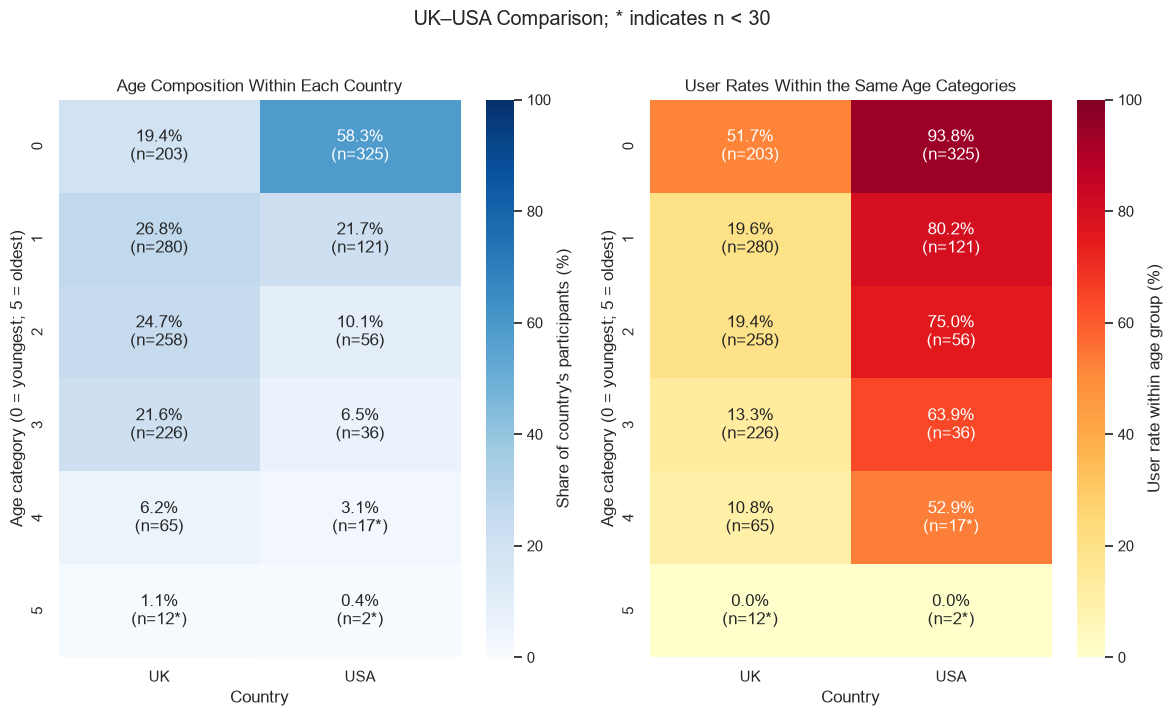

Youngest-category share:
Country
UK     19.44
USA    58.35


In [3]:
selected = data_clean[data_clean["Country"].isin(["UK", "USA"])].copy()
age_order = sorted(data_clean["Age"].unique())
country_order = ["UK", "USA"]

age_country = (
    selected.groupby(["Age", "Country"])["User"]
    .agg(n="count", users="sum")
    .reset_index()
)
age_country["User rate (%)"] = 100 * age_country["users"] / age_country["n"]
low, high = wilson_interval(age_country["users"], age_country["n"])
age_country["95% CI lower (%)"] = 100 * low
age_country["95% CI upper (%)"] = 100 * high
display(age_country.round(2))

counts = (
    age_country.pivot(index="Age", columns="Country", values="n")
    .reindex(index=age_order, columns=country_order).fillna(0).astype(int)
)
composition = counts.div(counts.sum(axis=0), axis=1) * 100
rates = (
    age_country.pivot(index="Age", columns="Country", values="User rate (%)")
    .reindex(index=age_order, columns=country_order)
)

def cell_labels(values):
    labels = pd.DataFrame("", index=values.index, columns=values.columns)
    for age in values.index:
        for country in values.columns:
            value = values.loc[age, country]
            size = counts.loc[age, country]
            if pd.notna(value) and size > 0:
                flag = "*" if size < 30 else ""
                labels.loc[age, country] = f"{value:.1f}%\n(n={size}{flag})"
    return labels

fig, axes = plt.subplots(1, 2, figsize=(12, 7))
sns.heatmap(
    composition, annot=cell_labels(composition), fmt="", cmap="Blues",
    vmin=0, vmax=100, ax=axes[0],
    cbar_kws={"label": "Share of country's participants (%)"}
)
axes[0].set_title("Age Composition Within Each Country")
sns.heatmap(
    rates, annot=cell_labels(rates), fmt="", cmap="YlOrRd",
    vmin=0, vmax=100, ax=axes[1],
    cbar_kws={"label": "User rate within age group (%)"}
)
axes[1].set_title("User Rates Within the Same Age Categories")
for ax in axes:
    ax.set_xlabel("Country")
    ax.set_ylabel("Age category (0 = youngest; 5 = oldest)")
fig.suptitle("UK–USA Comparison; * indicates n < 30", y=1.02)
fig.tight_layout()
plt.show()

print("Youngest-category share:")
print((composition.loc[0]).round(2).to_string())


## Findings and implications

- **Age composition differs:** Age = 0 accounts for **19.4% of UK participants**, versus **58.3% of USA participants**. The overall country comparison therefore mixes different age compositions.
- **The country difference remains within age categories:** for Age = 0, the User rate is **51.7% in the UK versus 93.8% in the USA**; for Age = 1, it is **19.6% versus 80.2%**. Age composition alone does not fully explain the observed difference. This is descriptive stratification, not proof of an independent country effect.
- **Sparse groups need caution:** Age = 5 contains only 12 UK and 2 USA participants, all Non-Users. A zero observed rate does not establish a zero population rate; consult the confidence intervals.
- **Feature exclusion does not remove sample composition:** keeping Country out of the prediction model does not eliminate its association with age or personality features, nor make the sample representative of other countries.

### Further investigation

1. Compare the personality–User associations separately within UK and USA before generalizing the pooled correlation heatmap.
2. Fit an exploratory logistic regression with categorical Country, Age and Education, Gender, and personality scores to assess adjusted associations. Check sparse categories and uncertainty before interpreting coefficients.
3. Report model performance separately for UK and USA. A country-held-out evaluation can additionally examine transfer between these settings, but answers a different question from the existing random train/test split.

All percentages describe this survey sample and the combined eight-substance target. They should not be interpreted as national prevalence, causal effects, or future consumption risk.
